<a href="https://colab.research.google.com/github/rajmatondkar3-eng/CSL701-CS30_Machine-Learning-Lab/blob/main/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Raj Shriram Matondkar

Batch : CS-02


Roll Number :CS-30



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load dataset in Google Colab
from google.colab import files
uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the dataset
print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
First five rows:
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset shape: (3430, 11)

Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_leng

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Identify the required columns, supporting alternative dataset names
def find_column(candidates):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"None of these columns were found: {candidates}\n"
        f"Available columns: {df.columns.tolist()}"
    )

species_col = find_column(["species"])
length_col = find_column(["culmen_length_mm", "bill_length_mm"])
depth_col = find_column(["culmen_depth_mm", "bill_depth_mm"])
flipper_col = find_column(["flipper_length_mm"])
mass_col = find_column(["body_mass_g"])

# Select features and target
feature_cols = [
    length_col,
    depth_col,
    flipper_col,
    mass_col
]

data = df[feature_cols + [species_col]].copy()

# Convert feature columns to numeric values
for col in feature_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Handle missing values
data = data.dropna(subset=feature_cols + [species_col])

# Remove rows with missing or blank species labels
data = data[data[species_col].astype(str).str.strip() != ""]

X = data[feature_cols]
y = LabelEncoder().fit_transform(data[species_col].astype(str).str.strip())

# Save the encoder to display species names later
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data[species_col].astype(str).str.strip())

print("Selected features:")
print(feature_cols)

print("\nSpecies classes:")
print(label_encoder.classes_)

print("\nMissing values after preprocessing:")
print(data[feature_cols + [species_col]].isnull().sum())

print("\nCleaned dataset shape:", data.shape)
print("\nTarget distribution:")
print(data[species_col].value_counts())

Selected features:
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

Species classes:
['Adelie' 'Chinstrap' 'Gentoo']

Missing values after preprocessing:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64

Cleaned dataset shape: (3430, 5)

Target distribution:
species
Adelie       1560
Gentoo       1247
Chinstrap     623
Name: count, dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training samples: 2744
Testing samples: 686
Training features shape: (2744, 4)
Testing features shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# Create the CART decision tree classifier
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train the model
cart_model.fit(X_train, y_train)

# Predict species on the test data
y_pred_cart = cart_model.predict(X_test)

print("CART model trained successfully!")
print("Predicted classes:", y_pred_cart[:10])
print("Actual classes:   ", y_test[:10])

CART model trained successfully!
Predicted classes: [2 2 0 0 2 2 1 0 0 0]
Actual classes:    [0 2 0 0 0 2 1 0 2 0]


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Accuracy: 45.19 %

CART Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]


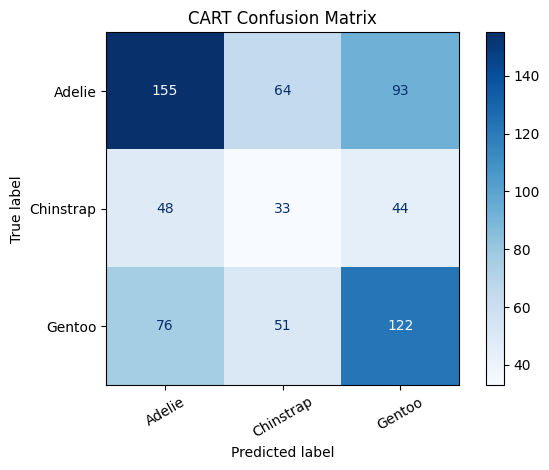


CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



In [ ]:
# Calculate accuracy
cart_accuracy = accuracy_score(y_test, y_pred_cart)
print("CART Accuracy:", round(cart_accuracy * 100, 2), "%")

# Generate confusion matrix
cm_cart = confusion_matrix(
    y_test,
    y_pred_cart,
    labels=np.arange(len(label_encoder.classes_))
)

print("\nCART Confusion Matrix:")
print(cm_cart)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cart,
    display_labels=label_encoder.classes_
)
disp.plot(cmap="Blues", values_format="d")
plt.title("CART Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Classification report
print("\nCART Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_cart,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


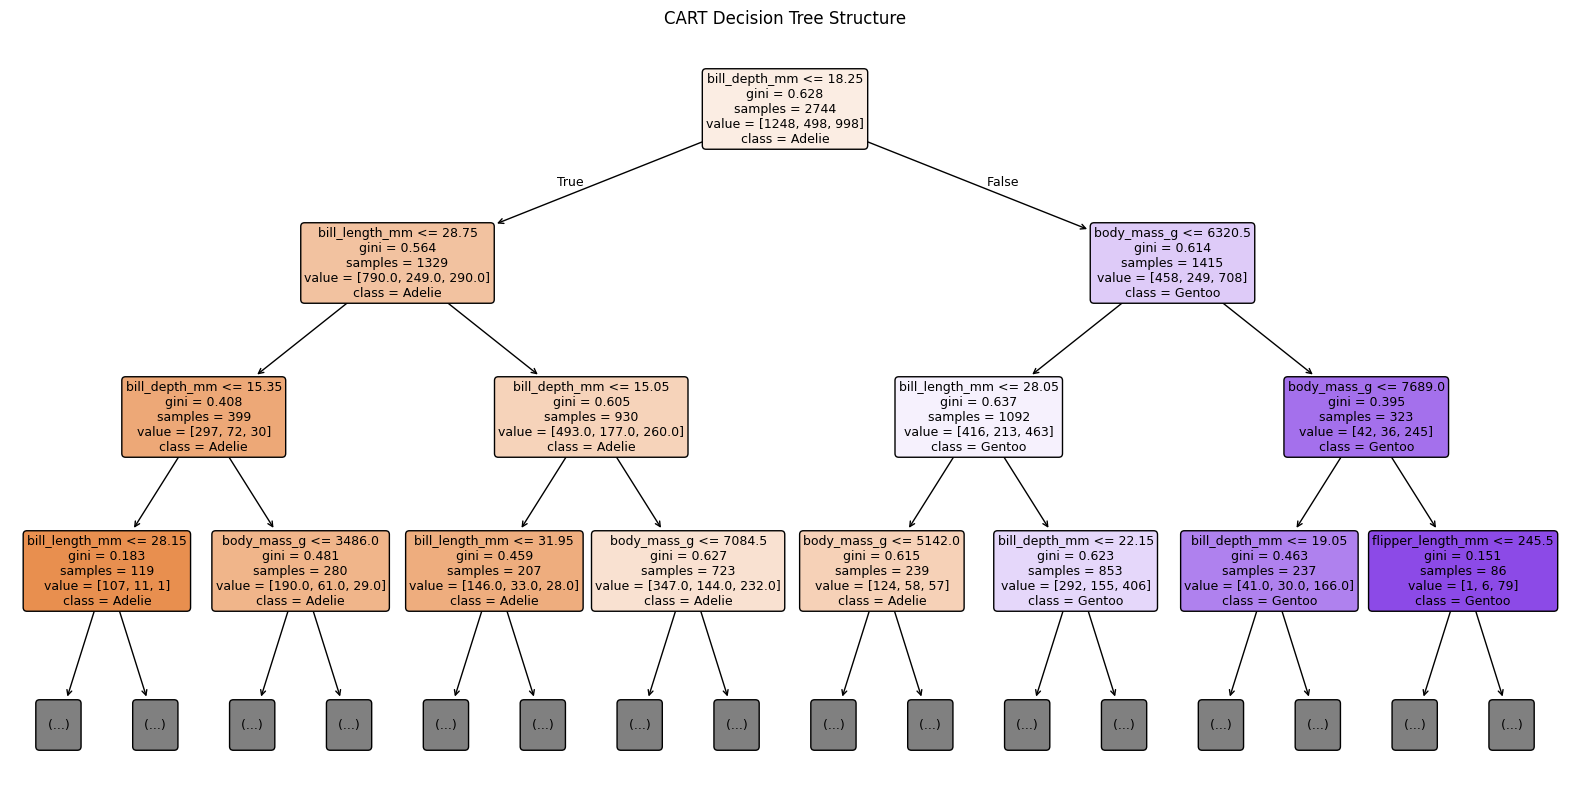

2D CART Accuracy: 43.88 %


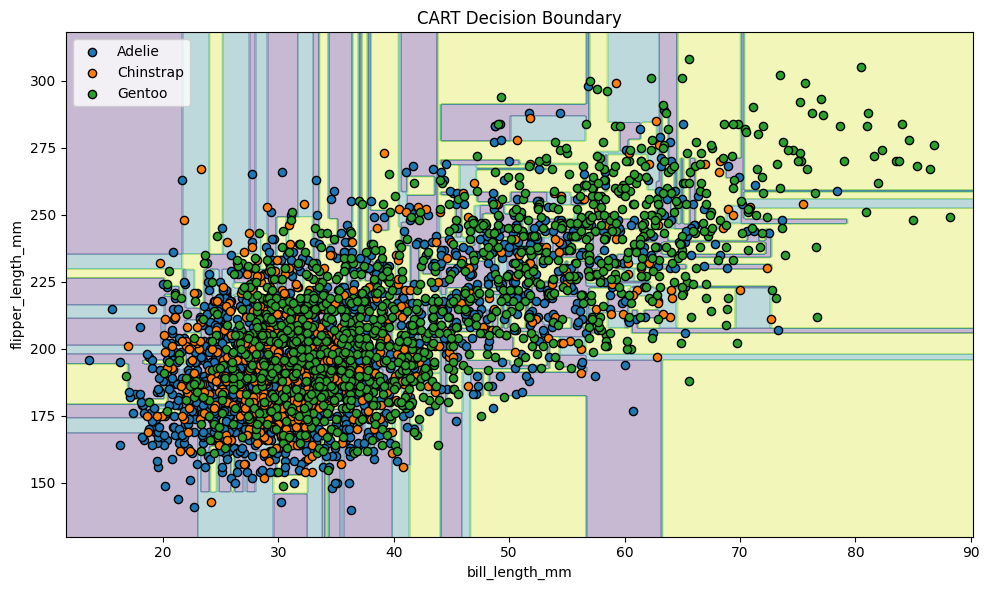

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=feature_cols,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("CART Decision Tree Structure")
plt.show()

# Select two features for 2D visualization
features_2d = [length_col, flipper_col]

X2 = data[features_2d]
y2 = label_encoder.transform(
    data[species_col].astype(str).str.strip()
)

# Split the 2D dataset
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

# Train the 2D CART model
cart_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_2d.fit(X2_train, y2_train)

print("2D CART Accuracy:",
      round(cart_2d.score(X2_test, y2_test) * 100, 2), "%")

# Create a mesh grid
x_min, x_max = X2[features_2d[0]].min() - 2, X2[features_2d[0]].max() + 2
y_min, y_max = X2[features_2d[1]].min() - 10, X2[features_2d[1]].max() + 10

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predict each point in the grid
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features_2d
)
Z = cart_2d.predict(grid).reshape(xx.shape)

# Plot decision regions and data points
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

for i, species in enumerate(label_encoder.classes_):
    mask = y2 == i
    plt.scatter(
        X2.loc[mask, features_2d[0]],
        X2.loc[mask, features_2d[1]],
        label=species,
        edgecolors="black",
        s=35
    )

plt.xlabel(features_2d[0])
plt.ylabel(features_2d[1])
plt.title("CART Decision Boundary")
plt.legend()
plt.tight_layout()
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

2D Logistic Regression Accuracy: 52.62 %


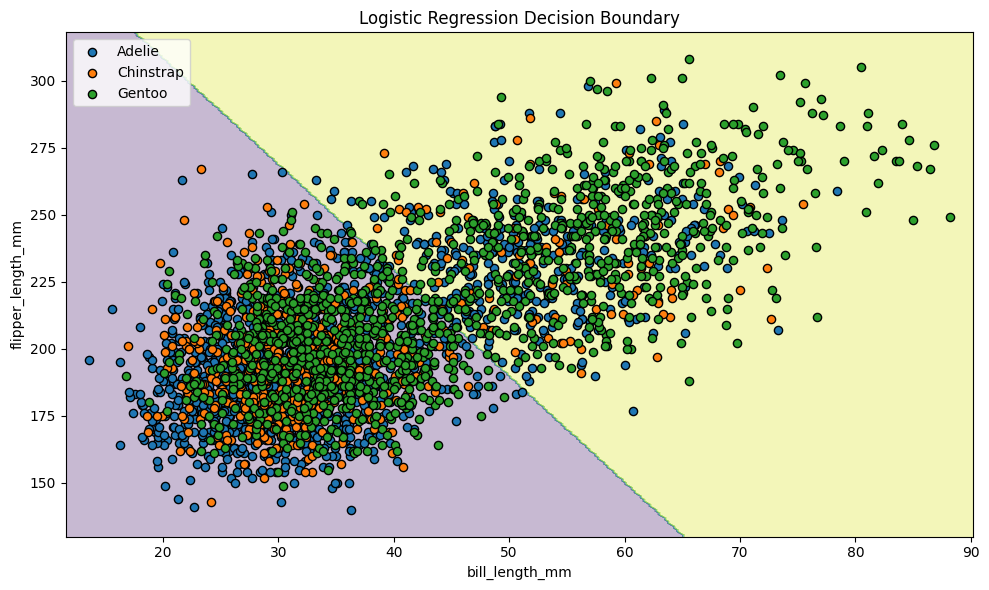

In [ ]:
# Standardize the two selected features
scaler_2d = StandardScaler()

X2_train_scaled = scaler_2d.fit_transform(X2_train)
X2_test_scaled = scaler_2d.transform(X2_test)

# Create and train Logistic Regression
logistic_2d = LogisticRegression(max_iter=1000)

logistic_2d.fit(X2_train_scaled, y2_train)

# Predict test classes
y2_pred_logistic = logistic_2d.predict(X2_test_scaled)

# Evaluate accuracy
logistic_2d_accuracy = accuracy_score(
    y2_test,
    y2_pred_logistic
)

print(
    "2D Logistic Regression Accuracy:",
    round(logistic_2d_accuracy * 100, 2),
    "%"
)

# Generate a grid in the original feature units
xx, yy = np.meshgrid(
    np.linspace(X2[features_2d[0]].min() - 2,
                X2[features_2d[0]].max() + 2, 300),
    np.linspace(X2[features_2d[1]].min() - 10,
                X2[features_2d[1]].max() + 10, 300)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features_2d
)

# Scale the grid using the fitted scaler
grid_scaled = scaler_2d.transform(grid)

Z_logistic = logistic_2d.predict(
    grid_scaled
).reshape(xx.shape)

# Plot linear classification regions
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z_logistic, alpha=0.3, cmap="viridis")

for i, species in enumerate(label_encoder.classes_):
    mask = y2 == i
    plt.scatter(
        X2.loc[mask, features_2d[0]],
        X2.loc[mask, features_2d[1]],
        label=species,
        edgecolors="black",
        s=35
    )

plt.xlabel(features_2d[0])
plt.ylabel(features_2d[1])
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.tight_layout()
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

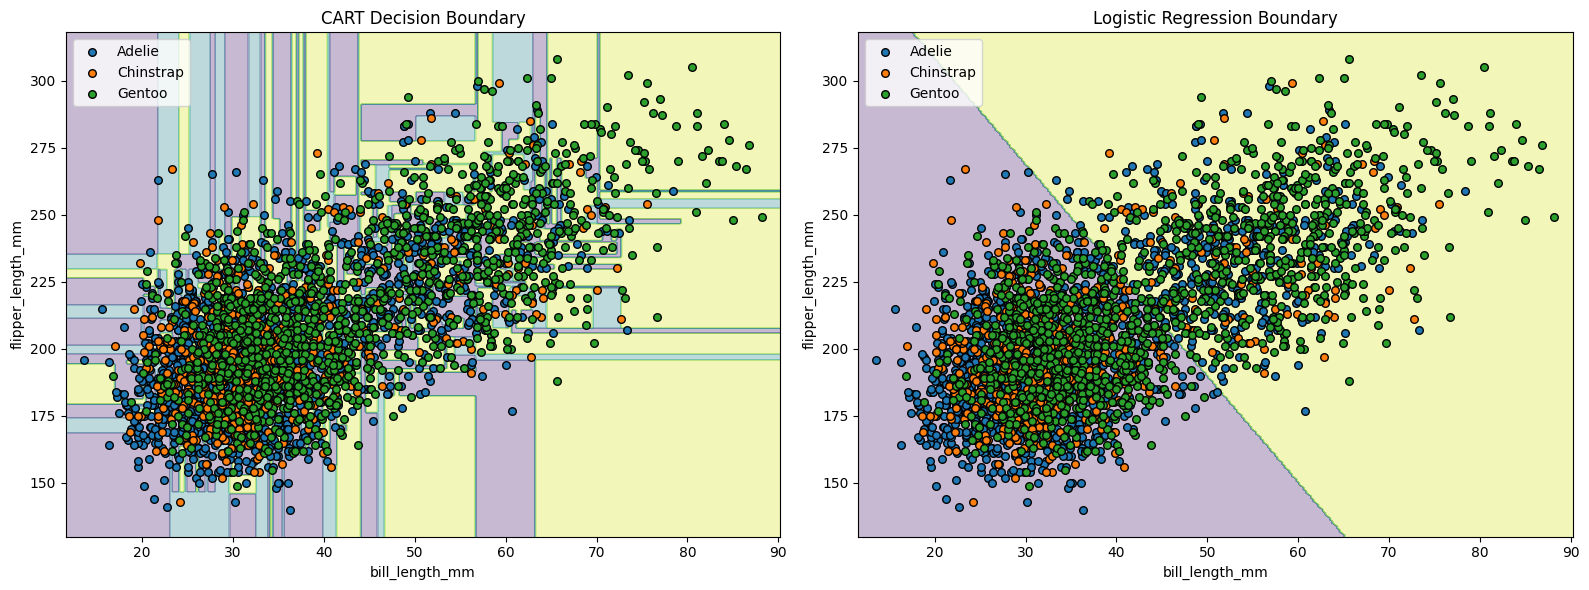

In [ ]:
# Predict regions using both models
Z_cart = cart_2d.predict(grid).reshape(xx.shape)

Z_logistic = logistic_2d.predict(
    scaler_2d.transform(grid)
).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CART boundary
axes[0].contourf(xx, yy, Z_cart, alpha=0.3, cmap="viridis")

for i, species in enumerate(label_encoder.classes_):
    mask = y2 == i
    axes[0].scatter(
        X2.loc[mask, features_2d[0]],
        X2.loc[mask, features_2d[1]],
        label=species,
        edgecolors="black",
        s=30
    )

axes[0].set_title("CART Decision Boundary")
axes[0].set_xlabel(features_2d[0])
axes[0].set_ylabel(features_2d[1])
axes[0].legend()

# Logistic Regression boundary
axes[1].contourf(xx, yy, Z_logistic, alpha=0.3, cmap="viridis")

for i, species in enumerate(label_encoder.classes_):
    mask = y2 == i
    axes[1].scatter(
        X2.loc[mask, features_2d[0]],
        X2.loc[mask, features_2d[1]],
        label=species,
        edgecolors="black",
        s=30
    )

axes[1].set_title("Logistic Regression Boundary")
axes[1].set_xlabel(features_2d[0])
axes[1].set_ylabel(features_2d[1])
axes[1].legend()

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

MODEL PERFORMANCE COMPARISON
----------------------------------------
CART Accuracy: 45.19%
Logistic Regression Accuracy: 57.87%


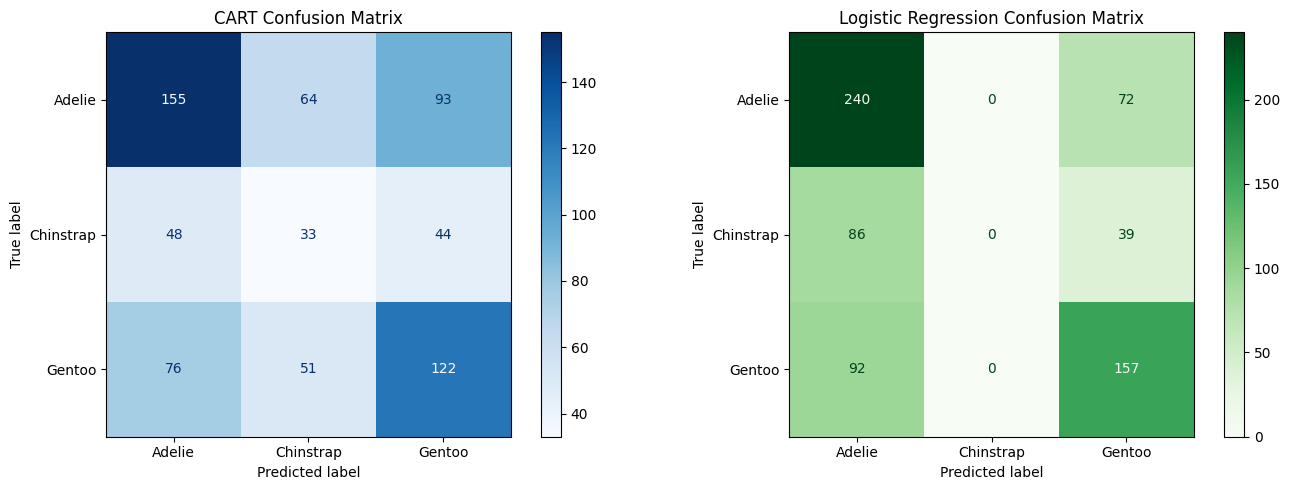


CART Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686


Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Adelie       0.57      0.77      0.66       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.59      0.63      0.61       249

    accuracy                           0.58       686
   macro avg       0.39      0.47      0.42       686
weighted avg       0.47      0.58      0.52       686



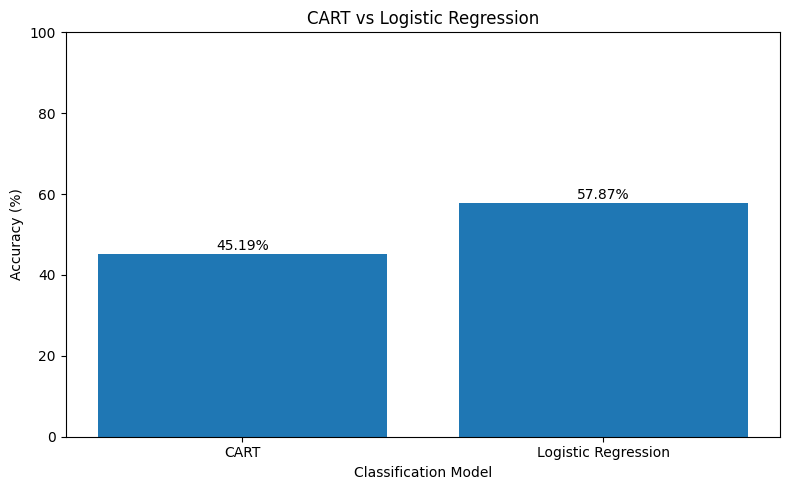

In [ ]:
# ---------------------------------------
# Train Logistic Regression on 4 features
# ---------------------------------------

# Standardize the training and testing features
scaler_full = StandardScaler()

X_train_scaled = scaler_full.fit_transform(X_train)
X_test_scaled = scaler_full.transform(X_test)

# Create and train the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test_scaled)


# ---------------------------------------
# Compare model accuracy
# ---------------------------------------

cart_accuracy = accuracy_score(y_test, y_pred_cart)

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("MODEL PERFORMANCE COMPARISON")
print("-" * 40)
print(f"CART Accuracy: {cart_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy: {logistic_accuracy * 100:.2f}%")


# ---------------------------------------
# Confusion matrices
# ---------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_cart,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap="Blues",
    ax=axes[0],
    values_format="d"
)
axes[0].set_title("CART Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap="Greens",
    ax=axes[1],
    values_format="d"
)
axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()


# ---------------------------------------
# Classification reports
# ---------------------------------------

print("\nCART Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_cart,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

print("\nLogistic Regression Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


# ---------------------------------------
# Accuracy comparison chart
# ---------------------------------------

models = ["CART", "Logistic Regression"]
accuracies = [cart_accuracy * 100, logistic_accuracy * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("Classification Model")
plt.title("CART vs Logistic Regression")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.